# Reynolds operating regimes: causal identification and Stage 1 bias

**Research questions:** (1) Does setting a higher Reynolds level change healthy Stage 1 error? (2) Do Reynolds ramps add transient error? (3) Does Reynolds make Stage 1 systematically over- or underpredict individual acoustic channels?

**Design:** An observational, single-run quasi-experimental feasibility assessment. No intervention is randomized. A correlation, a HAC regression, and a before/after comparison are **not** automatically causal estimates. We explicitly check whether DiD is identifiable and do not manufacture a control group.

**Data limitation:** The healthy endpoint export provides RMSE, MAE, and actual-spectrum RMS, but **not signed time-resolved 108-channel residuals**. Therefore directional over/underprediction **cannot** be estimated from this file. A separate aggregate channel summary is available, but it does not identify a causal signed-bias effect. The original Stage 1 inference must be rerun/exported to answer the directional question fully.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
from IPython.display import display
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
candidates=[ROOT/'results'/'stage1_reynolds_tracking'/'1212_1_healthy_stage1_endpoints.csv',ROOT/'results'/'1212_1_healthy_stage1_endpoints.csv',Path('/mnt/data/work_stage/stage1_reynolds_tracking/1212_1_healthy_stage1_endpoints.csv')]
source=next((p for p in candidates if p.exists()),None)
if source is None: raise FileNotFoundError('Place extracted stage1_reynolds_tracking/ under results/')
OUT=(ROOT/'results'/'reynolds_causal_full') if (ROOT/'results').exists() else Path('/mnt/data/reynolds_causal_full')
OUT.mkdir(parents=True,exist_ok=True)
d=pd.read_csv(source).sort_values('observation_index').reset_index(drop=True)
d['t']=d.observation_index.astype(float)
d['adjacent']=d.observation_index.diff().eq(1)
d['dRe']=d.Reynolds.diff().where(d.adjacent)
d['dRMSE']=d.endpoint_RMSE.diff().where(d.adjacent)
d['ramp']=d.dRe.abs().gt(.001)
d['direction']=np.select([d.dRe.gt(.001),d.dRe.lt(-.001)],['up','down'],default='stable')
print('Input:',source,'rows:',len(d),'adjacent pairs:',d.adjacent.sum())
print('Signed residual columns:',[c for c in d if 'residual' in c.lower()])
display(d[['Reynolds','endpoint_RMSE','relative_RMSE','dRe']].describe().round(3))

Input: /mnt/data/work_stage/stage1_reynolds_tracking/1212_1_healthy_stage1_endpoints.csv rows: 7567 adjacent pairs: 7561
Signed residual columns: []


,Reynolds,endpoint_RMSE,relative_RMSE,dRe
count,7567.000,7567.000,7567.000,7561.000
mean,55.730,2.398,0.095,0.001
std,48.490,0.597,0.018,0.060
min,0.000,1.516,0.065,-0.167
25%,14.844,2.052,0.085,0.000
50%,41.667,2.237,0.091,0.000
75%,100.000,2.574,0.099,0.021
max,150.000,14.099,0.364,0.083


## 1. Physical regime segmentation
A **sample** is one healthy endpoint (one second in the supplied timeline). A **channel** is one sensor × one frequency. A **band** is a numeric interval of Reynolds. A **ramp** is a contiguous stretch of increasing or decreasing Reynolds; a **plateau** is a contiguous stretch with nearly constant Reynolds. An **event** below is a plateau onset, not a single large per-second increment. Gaps across excluded leaking intervals break segments.

Segment count: 18 ramp segments: 6 plateaus: 12


,direction,start_index,end_index,n,Re_start,Re_end,rmse_start,rmse_end,total_Re_change,segment_type
1,up,41,2401,2361,13.333332,150.0000,2.099406,2.682916,136.666668,ramp
17,stable,9902,10801,900,0.000000,0.0000,2.286255,1.800709,0.000000,plateau
11,stable,6902,7500,599,25.000000,25.0000,2.380549,3.381030,0.000000,plateau
2,stable,2402,3000,599,150.000000,150.0000,2.981184,9.626793,0.000000,plateau
8,stable,5402,6000,599,50.000000,50.0000,3.514305,2.721851,0.000000,plateau
5,stable,3902,4500,599,100.000000,100.0000,4.006638,3.502346,0.000000,plateau
14,stable,8402,9000,599,12.500000,12.5000,2.526577,2.838651,0.000000,plateau
16,down,9641,9901,261,10.833333,0.0000,2.007635,2.128357,-10.833333,ramp
7,down,5141,5401,261,93.333336,50.0000,2.255440,3.325151,-43.333336,ramp
4,down,3641,3901,261,143.333330,100.0000,2.852963,4.743215,-43.333330,ramp


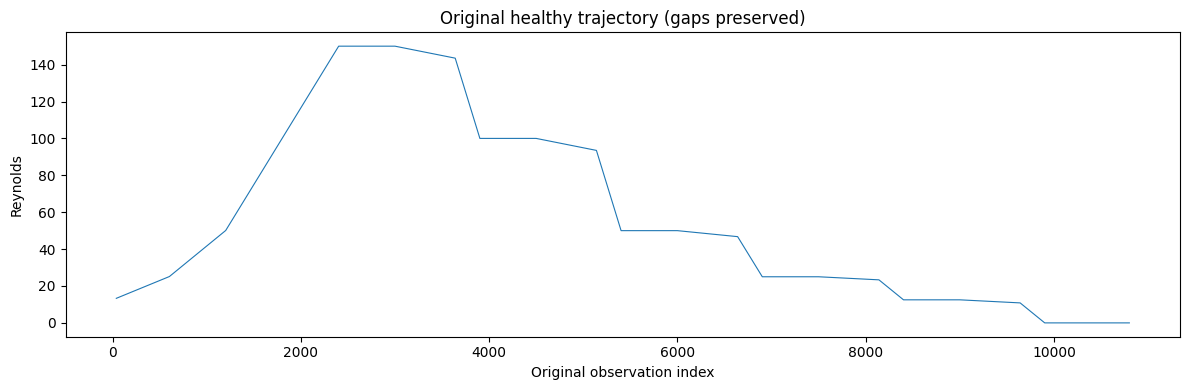

In [2]:
breaks=(~d.adjacent)|d.direction.ne(d.direction.shift())
d['segment_id']=breaks.cumsum()
segments=d.groupby('segment_id').agg(direction=('direction','first'),start_index=('observation_index','first'),end_index=('observation_index','last'),n=('t','size'),Re_start=('Reynolds','first'),Re_end=('Reynolds','last'),rmse_start=('endpoint_RMSE','first'),rmse_end=('endpoint_RMSE','last')).reset_index(drop=True)
segments['total_Re_change']=segments.Re_end-segments.Re_start
segments['segment_type']=np.where(segments.direction=='stable','plateau','ramp')
segments.to_csv(OUT/'physical_segments.csv',index=False)
print('Segment count:',len(segments),'ramp segments:',sum(segments.segment_type=='ramp'),'plateaus:',sum(segments.segment_type=='plateau'))
display(segments.sort_values('n',ascending=False).head(20))
fig,ax=plt.subplots(figsize=(12,4));ax.plot(d.t,d.Reynolds,lw=.8);ax.set(xlabel='Original observation index',ylabel='Reynolds',title='Original healthy trajectory (gaps preserved)');fig.tight_layout();fig.savefig(OUT/'reynolds_trajectory.png',dpi=150);plt.show()

## 2. What would a causal comparison require?
A **Reynolds-level intervention** would compare the same physical system under different externally assigned flow regimes, holding relevant conditions fixed. A **transition intervention** would compare a recently ramped system against a system at the same Reynolds level that had not just ramped. This single time series contains neither a randomized assignment nor a concurrent untreated control. **Conventional DiD is not identified:** the same system cannot be both treated and untreated at the same time, and using a different time period as a control does not establish parallel trends. We therefore do not report a DiD ATT. The models below estimate conditional associations, not causal effects.

In [3]:
# Common support of Reynolds level across time quartiles; weak overlap flags time confounding.
d['time_quartile']=pd.qcut(d.t,4,labels=['Q1','Q2','Q3','Q4'])
d['Re_band']=pd.cut(d.Reynolds,[-np.inf,10,25,50,75,100,125,np.inf],right=False)
coverage=pd.crosstab(d.Re_band,d.time_quartile)
coverage.to_csv(OUT/'overlap.csv')
display(coverage)
print('Re-time correlation:',round(d[['Reynolds','t']].corr().iloc[0,1],3))
print('DiD identification: NOT established (no concurrent comparison unit and no credible parallel-trends evidence).')

time_quartile,Q1,Q2,Q3,Q4
Re_band,,,,
"[-inf, 10.0)",0,0,0,1140
"[10.0, 25.0)",561,0,131,752
"[25.0, 50.0)",600,0,861,0
"[50.0, 75.0)",300,0,749,0
"[75.0, 100.0)",300,0,112,0
"[100.0, 125.0)",131,880,38,0
"[125.0, inf)",0,1012,0,0


Re-time correlation: -0.567
DiD identification: NOT established (no concurrent comparison unit and no credible parallel-trends evidence).


## 3. Adjusted level and ramp associations (HAC uncertainty)
We estimate the following *working model*, separately for endpoint RMSE and relative RMSE:

\[Y_t=eta_0+eta_1(Re_t/100)+eta_2(Re_t/100)^2+eta_3 I(\mathrm{ramp}_t)+eta_4 I(\mathrm{down}_t)+\gamma_1 u_t+\gamma_2 u_t^2+\gamma_3 u_t^3+\epsilon_t\]

where \(u_t\) is standardized experiment time. \(eta_1\) and \(eta_2\) describe the *conditional shape* of the Reynolds-level association; \(eta_3\) describes the adjusted ramp-versus-plateau association; \(eta_4\) describes any extra difference for descending ramps. HAC (Newey–West) standard errors account approximately for autocorrelation, **not unmeasured confounding**. Time and Reynolds are highly entangled, so coefficients may be unstable.

In [4]:
u=(d.t-d.t.mean())/d.t.std();r=d.Reynolds/100
X=pd.DataFrame({'intercept':1.,'Re_100':r,'Re_100_sq':r*r,'ramp':d.ramp.astype(float),'descending':d.direction.eq('down').astype(float),'time':u,'time_sq':u*u,'time_cube':u*u*u})
records=[]
for y in ['endpoint_RMSE','relative_RMSE','endpoint_MAE']:
    fit=sm.OLS(d[y],X).fit(cov_type='HAC',cov_kwds={'maxlags':60})
    for name in X.columns:
        records.append({'outcome':y,'term':name,'coefficient':fit.params[name],'se_HAC':fit.bse[name],'p_HAC':fit.pvalues[name],'ci_low':fit.conf_int().loc[name,0],'ci_high':fit.conf_int().loc[name,1],'R2':fit.rsquared})
res=pd.DataFrame(records);res.to_csv(OUT/'adjusted_regressions.csv',index=False)
display(res.loc[res.term.isin(['Re_100','Re_100_sq','ramp','descending'])].round(5))
print('CAUTION: adjusted association, not identified causal effect.')

,outcome,term,coefficient,se_HAC,p_HAC,ci_low,ci_high,R2
1,endpoint_RMSE,Re_100,1.68484,0.73824,0.02248,0.23792,3.13177,0.32618
2,endpoint_RMSE,Re_100_sq,-0.46443,0.33912,0.17084,-1.12909,0.20024,0.32618
3,endpoint_RMSE,ramp,0.17791,0.13458,0.18620,-0.08587,0.44169,0.32618
4,endpoint_RMSE,descending,0.23936,0.19594,0.22185,-0.14467,0.62340,0.32618
9,relative_RMSE,Re_100,0.06408,0.02869,0.02551,0.00785,0.12032,0.17645
10,relative_RMSE,Re_100_sq,-0.02471,0.01319,0.06105,-0.05057,0.00115,0.17645
11,relative_RMSE,ramp,0.01192,0.00482,0.01339,0.00247,0.02137,0.17645
12,relative_RMSE,descending,-0.00024,0.00661,0.97128,-0.01320,0.01272,0.17645
17,endpoint_MAE,Re_100,1.12789,0.51035,0.02710,0.12763,2.12816,0.31168
18,endpoint_MAE,Re_100_sq,-0.29732,0.23200,0.20000,-0.75203,0.15739,0.31168


CAUTION: adjusted association, not identified causal effect.


## 4. Instantaneous first differences
A **first difference** is the change between genuinely adjacent healthy seconds, \(\Delta Y_t=Y_t-Y_{t-1}\). We fit \(\Delta RMSE_t=lpha+	heta_1\Delta Re_t+	heta_2|\Delta Re_t|+\epsilon_t\). This tests **immediate** error changes only, not cumulative level changes or delayed recovery. Differencing is **not Difference-in-Differences**.

In [5]:
z=d.dropna(subset=['dRe','dRMSE']).copy()
Z=sm.add_constant(pd.DataFrame({'dRe':z.dRe,'abs_dRe':z.dRe.abs()}))
fd=sm.OLS(z.dRMSE,Z).fit(cov_type='HAC',cov_kwds={'maxlags':60})
fd_table=pd.DataFrame({'coefficient':fd.params,'HAC_SE':fd.bse,'p':fd.pvalues,'CI_low':fd.conf_int()[0],'CI_high':fd.conf_int()[1]})
fd_table.to_csv(OUT/'first_difference.csv');display(fd_table.round(5))

,coefficient,HAC_SE,p,CI_low,CI_high
const,0.00119,0.00202,0.55648,-0.00277,0.00515
dRe,-0.01732,0.01784,0.33180,-0.05229,0.01766
abs_dRe,0.00533,0.02621,0.83875,-0.04604,0.05671


## 5. Ramp-end / plateau-onset interrupted-time-series diagnostics
Define a **meaningful ramp** as a contiguous monotonic segment with at least 30 adjacent samples and total Reynolds movement at least 2 units. At each ramp **end (plateau onset)**, inspect up to 120 seconds before and 120 seconds after, requiring complete healthy adjacency. We estimate a local segmented regression:

\[RMSE_{e,k}=lpha_e+\lambda_e k+	au_e I(k\geq0)+\delta_e kI(k\geq0)+\epsilon_{e,k}.\]

Here \(k\) is seconds from plateau onset, \(	au_e\) is an estimated **immediate discontinuity**, and \(\delta_e\) is a **slope change**. Since ramps develop gradually, a jump at plateau onset is not the full ramp effect. This is **descriptive interrupted time series**, not causal identification: there is no contemporaneous untreated control and changes may have been scheduled alongside other physical conditions.

Physical ramps meeting threshold: 6 with complete +/-120-second healthy data at plateau onset: 6


,plateau_onset,direction,ramp_n,total_Re_change,jump_at_onset,jump_p,slope_change_per_second,slope_p,pre_slope
0,2402,up,2361,136.66667,0.57651,0.00000,-0.01171,0.00000,0.00198
1,3902,down,261,-43.33333,-1.44422,0.00000,-0.00460,0.00824,-0.00030
2,5402,down,261,-43.33334,-0.55775,0.00000,-0.01063,0.00000,0.00631
3,6902,down,261,-21.66667,-0.88185,0.00000,-0.00179,0.34770,0.00388
4,8402,down,261,-10.83333,-0.15021,0.00703,-0.00160,0.12368,0.00253
5,9902,down,261,-10.83333,0.27349,0.02157,-0.00470,0.00005,0.00182


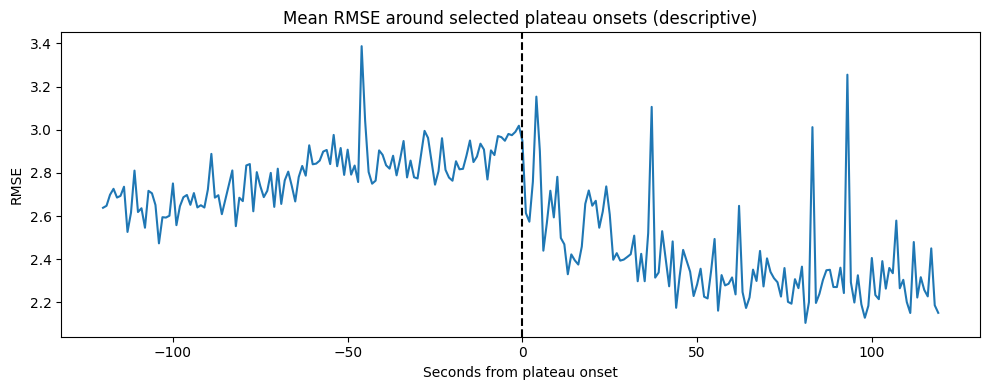

In [6]:
event_rows=[];profiles=[]
long_ramps=segments.query("segment_type == 'ramp' and n >= 30 and abs(total_Re_change) >= 2").copy()
for _,ev in long_ramps.iterrows():
    onset=int(ev.end_index)+1; sub=d.loc[d.observation_index.between(onset-120,onset+119)].copy()
    if len(sub)!=240 or not np.array_equal(sub.observation_index.to_numpy(),np.arange(onset-120,onset+120)):continue
    k=sub.observation_index.to_numpy()-onset; post=(k>=0).astype(float)
    mat=np.column_stack([np.ones(len(k)),k,post,k*post])
    fit=sm.OLS(sub.endpoint_RMSE.to_numpy(),mat).fit(cov_type='HAC',cov_kwds={'maxlags':20})
    event_rows.append({'plateau_onset':onset,'direction':ev.direction,'ramp_n':ev.n,'total_Re_change':ev.total_Re_change,'jump_at_onset':fit.params[2],'jump_p':fit.pvalues[2],'slope_change_per_second':fit.params[3],'slope_p':fit.pvalues[3],'pre_slope':fit.params[1]})
    profiles.extend([{'plateau_onset':onset,'relative_second':int(kk),'RMSE':float(v)} for kk,v in zip(k,sub.endpoint_RMSE)])
events=pd.DataFrame(event_rows);events.to_csv(OUT/'plateau_onset_ITS.csv',index=False)
print('Physical ramps meeting threshold:',len(long_ramps),'with complete +/-120-second healthy data at plateau onset:',len(events))
if len(events):
    display(events.round(5));p=pd.DataFrame(profiles);p.groupby('relative_second').RMSE.mean().plot(figsize=(10,4),title='Mean RMSE around selected plateau onsets (descriptive)');plt.axvline(0,color='black',ls='--');plt.xlabel('Seconds from plateau onset');plt.ylabel('RMSE');plt.tight_layout();plt.savefig(OUT/'plateau_onset_profile.png',dpi=150);plt.show()
else: print('Insufficient complete pre/post intervals: no event effect estimated. Do not relax criteria silently.')

## 6. Pre-trend and placebo feasibility
For each retained onset, the **pre-slope** indicates whether RMSE was already changing before the ramp. Nonzero pre-trends weaken simple before/after causal interpretations. A placebo onset on a plateau would be informative only if the plateau had comparable conditions and a sufficient uninterrupted observation window. Because this single trajectory lacks a defensible counterfactual, we **do not** use placebo outcomes to claim identification.

In [7]:
if len(events):
    print('Pre-ramp slope diagnostics:');display(events[['plateau_onset','direction','pre_slope','jump_at_onset','slope_change_per_second']].round(5))
    print('NOTE: selected ramp episodes share one experimental run and are not independent randomized trials.')
else: print('No complete ramp-onset event windows available; placebo comparison not identified.')

Pre-ramp slope diagnostics:


,plateau_onset,direction,pre_slope,jump_at_onset,slope_change_per_second
0,2402,up,0.00198,0.57651,-0.01171
1,3902,down,-0.00030,-1.44422,-0.00460
2,5402,down,0.00631,-0.55775,-0.01063
3,6902,down,0.00388,-0.88185,-0.00179
4,8402,down,0.00253,-0.15021,-0.00160
5,9902,down,0.00182,0.27349,-0.00470


NOTE: selected ramp episodes share one experimental run and are not independent randomized trials.


## 7. Directional overprediction / underprediction: not recoverable from RMSE
**Overprediction** means actual − predicted < 0. **Underprediction** means actual − predicted > 0. RMSE squares these differences and destroys the sign. The exported aggregate channel summary can reveal average signed bias and correlations but cannot support a causal time-resolved analysis. To test the main directional hypothesis, Stage 1 must export `observation_index`, `Reynolds`, `probe`, `frequency`, `actual`, `predicted`, and `signed_residual` for every healthy endpoint. We will not invent them.

In [8]:
summary_candidates=[ROOT/'results'/'reynolds_causal_results'/'channel_residual_diagnostics.csv',Path('/mnt/data/reynolds_causal_results/channel_residual_diagnostics.csv')]
cs=next((p for p in summary_candidates if p.exists()),None)
if cs:
    c=pd.read_csv(cs);display(c.sort_values('mean_signed_residual').head(8));display(c.sort_values('mean_signed_residual',ascending=False).head(8))
    print('These are average signed biases, NOT causal coefficients and NOT time-resolved intervention effects.')
else: print('No channel summary found; directional conclusion unavailable.')
print('REQUIRED next data export: 108 time-aligned signed residual channels (actual - predicted).')

,channel,n,mean_signed_residual,RMSE,corr_Re,corr_dRe_dResidual,corr_absdRe_absdResidual
0,DS_f250,7567,-8.918579,9.298696,0.005834,-0.000718,0.022696
7,DS_f160,7567,-2.503545,3.649545,-0.367481,-0.002393,0.020992
23,DS_f1600,7567,-2.375628,2.666432,-0.320589,-0.000939,0.062368
21,DS_f1250,7567,-2.350737,2.682627,-0.240616,-0.000819,0.077728
29,DS_f2000,7567,-2.186062,2.507408,-0.308900,-0.000461,0.103751
30,DS_f800,7567,-2.138108,2.495816,-0.214912,-0.000850,0.059413
39,US_f800,7567,-1.826239,2.362925,-0.042129,-0.000839,0.037601
43,DS_f1000,7567,-1.737008,2.263599,-0.334733,-0.000922,0.047317


,channel,n,mean_signed_residual,RMSE,corr_Re,corr_dRe_dResidual,corr_absdRe_absdResidual
1,US_f80,7567,5.824450,6.717864,0.364393,-0.001325,-0.038481
3,US_f31_5,7567,3.765193,5.142094,0.386857,-0.001806,-0.065542
8,US_f200,7567,2.991669,3.639706,-0.245221,-0.001322,0.054326
6,US_f100,7567,2.701303,4.017571,0.577816,-0.000759,-0.022935
5,US_f63,7567,2.692898,4.137846,0.624671,-0.001673,-0.039094
2,US_f50,7567,2.405955,5.226651,0.728883,-0.000821,-0.109261
14,US_f125,7567,2.303952,3.026797,0.336304,-0.000848,-0.011900
4,US_f40,7567,2.260018,4.469299,0.512375,-0.001936,-0.105283


These are average signed biases, NOT causal coefficients and NOT time-resolved intervention effects.
REQUIRED next data export: 108 time-aligned signed residual channels (actual - predicted).


## 8. Identification verdict
- **Identified:** descriptive associations, conditional HAC regression estimates, instantaneous first differences, and descriptive ramp-onset dynamics where enough healthy data exist.
- **Not identified:** causal effect of `do(Re=r)`; effect of ramps separated from pump/operating conditions; conventional DiD ATT; causal over/underprediction by channel; mediation into Stage 2 false alarms.
- **Needed to establish causality:** externally controlled/repeated Reynolds settings with comparable conditions, preferably randomized or counterbalanced order; measured pump/pressure/temperature state; repeated independent runs; time-resolved signed residuals; and eventually Stage 2 false-alarm timestamps.

**No retraining performed.** The key scientific outcome may be a documented identification failure; that is preferable to falsely labeling a regression coefficient causal.